# 14 — FINAL DYNAMIC SIMULATION

The full integrated simulation (Section 23-24), built entirely on the
real Day 1-4 engine — nothing here is a separate scripted demo:

- **Live map**: robots, tasks, zones, obstacles, charging stations, A* paths
- **Dynamic network flow graph**: SOURCE -> Robots -> Tasks -> SINK, with
  feasible / battery-blocked / selected edges visually distinguished
- **Side panel**: sim time, active/completed tasks, per-robot SOC,
  current allocations, Jain fairness, emergency status, last event,
  reallocation count
- **Before/after graph snapshots** (Section 23's exact required example)
- **An animated GIF** stepping through the real event timeline

This notebook runs the actual `reallocation.Simulator` engine from Day 3,
rendered through `simulation.py`'s dashboard (Day 4) — end to end, start
to finish, as the spec requires by the end of Day 4.

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import copy
from IPython.display import Image, display

from reallocation import Simulator
from events import Event, apply_event
from simulation import render_frame, render_before_after, make_animation

DATASET_ROOT = "../data/dataset"


## 1. Dashboard snapshot at t=0 (initial allocation)

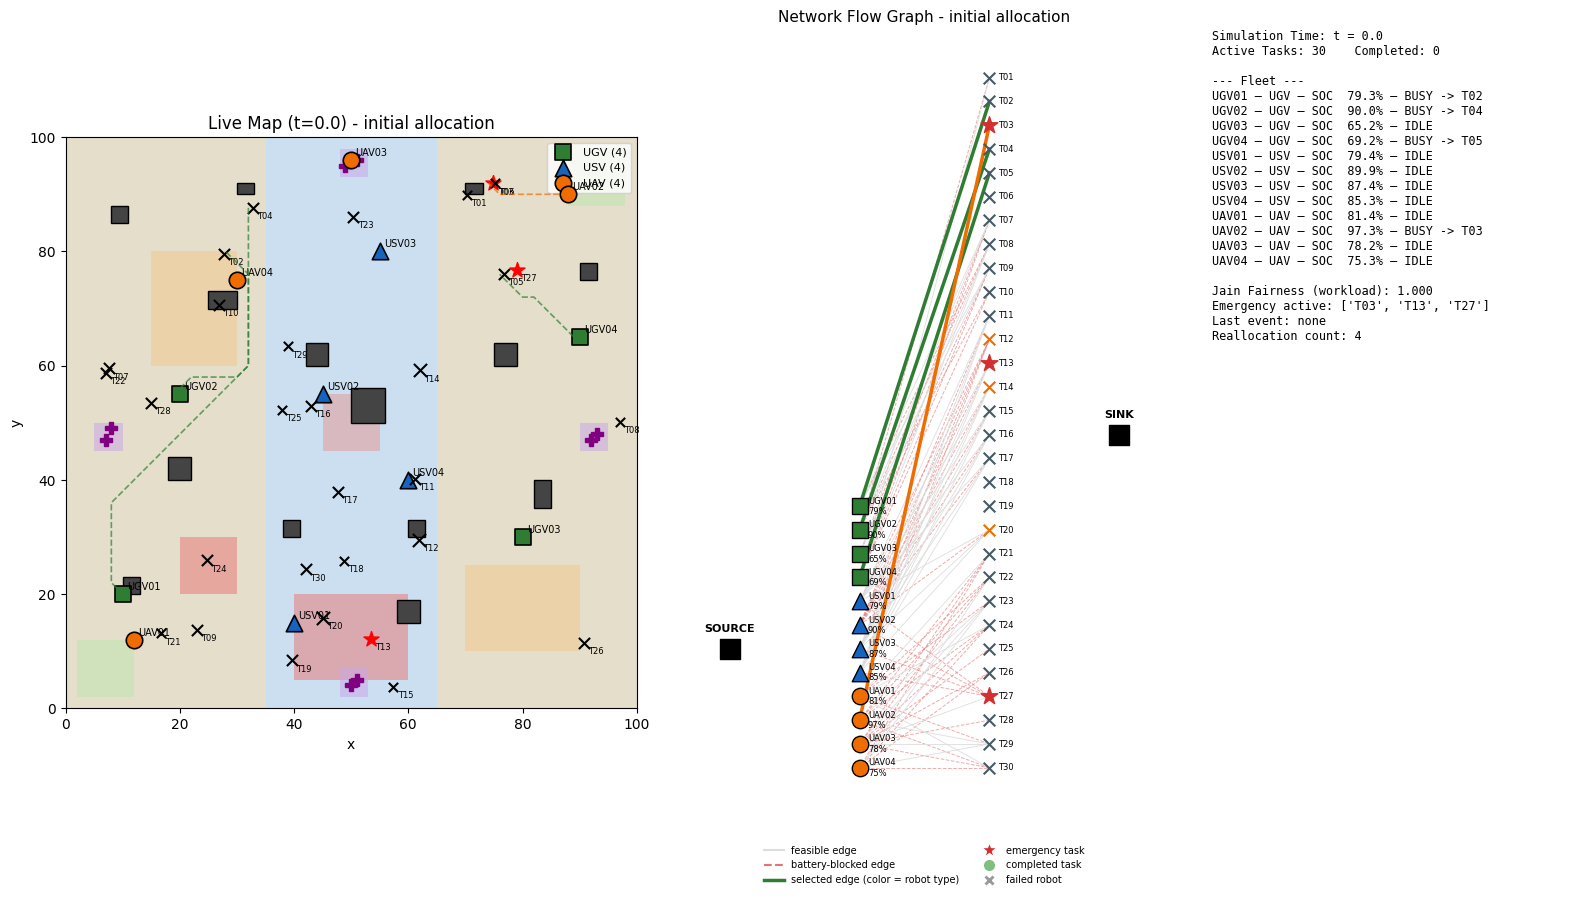

In [2]:
sim = Simulator(dataset_root=DATASET_ROOT, run_id="final_sim_t0")
sim._allocate(t=0.0)
fig = render_frame(sim, title_suffix="- initial allocation")
fig.savefig("../results/day4_dashboard_t0.png", dpi=130, bbox_inches="tight")


## 2. Section 23's required example: BEFORE / AFTER graph updates

### 2a. Emergency task appears -> new edge/allocation

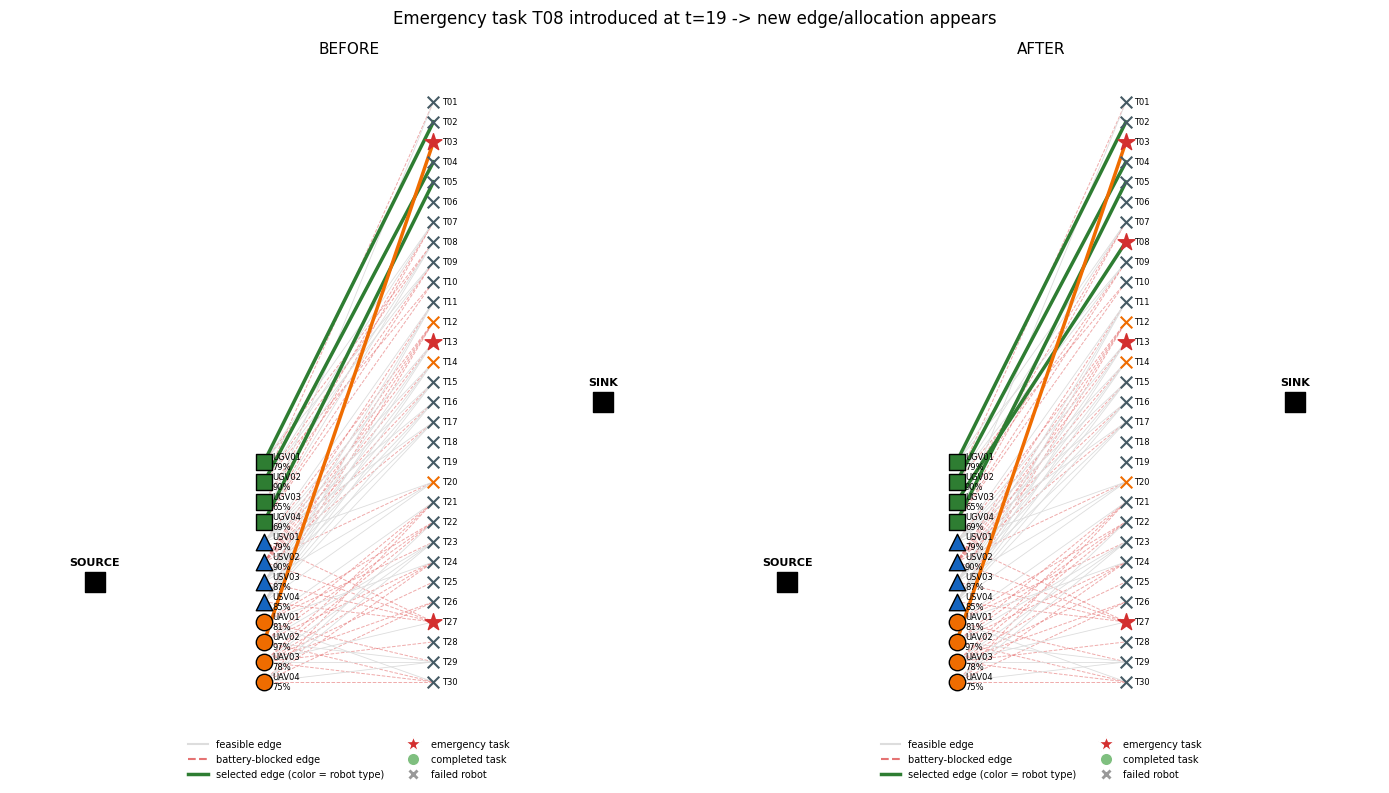

In [3]:
sim_before = Simulator(dataset_root=DATASET_ROOT, run_id="final_before1")
sim_before._allocate(t=0.0)

sim_after = copy.deepcopy(sim_before)
ev = Event(event_id="DEMO_EMG", time=19.0, event_type="NEW_EMERGENCY",
           task_id="T08", robot_id=None, zone_id=None, severity=5)
apply_event(ev, sim_after.fleet, sim_after.tm, sim_after.env)
sim_after.t = 19.0
sim_after._allocate(t=19.0)

render_before_after(sim_before, sim_after,
                     "Emergency task T08 introduced at t=19 -> new edge/allocation appears",
                     savepath="../results/day4_before_after_emergency.png");


### 2b. Robot's SOC drops -> its feasible edges shrink

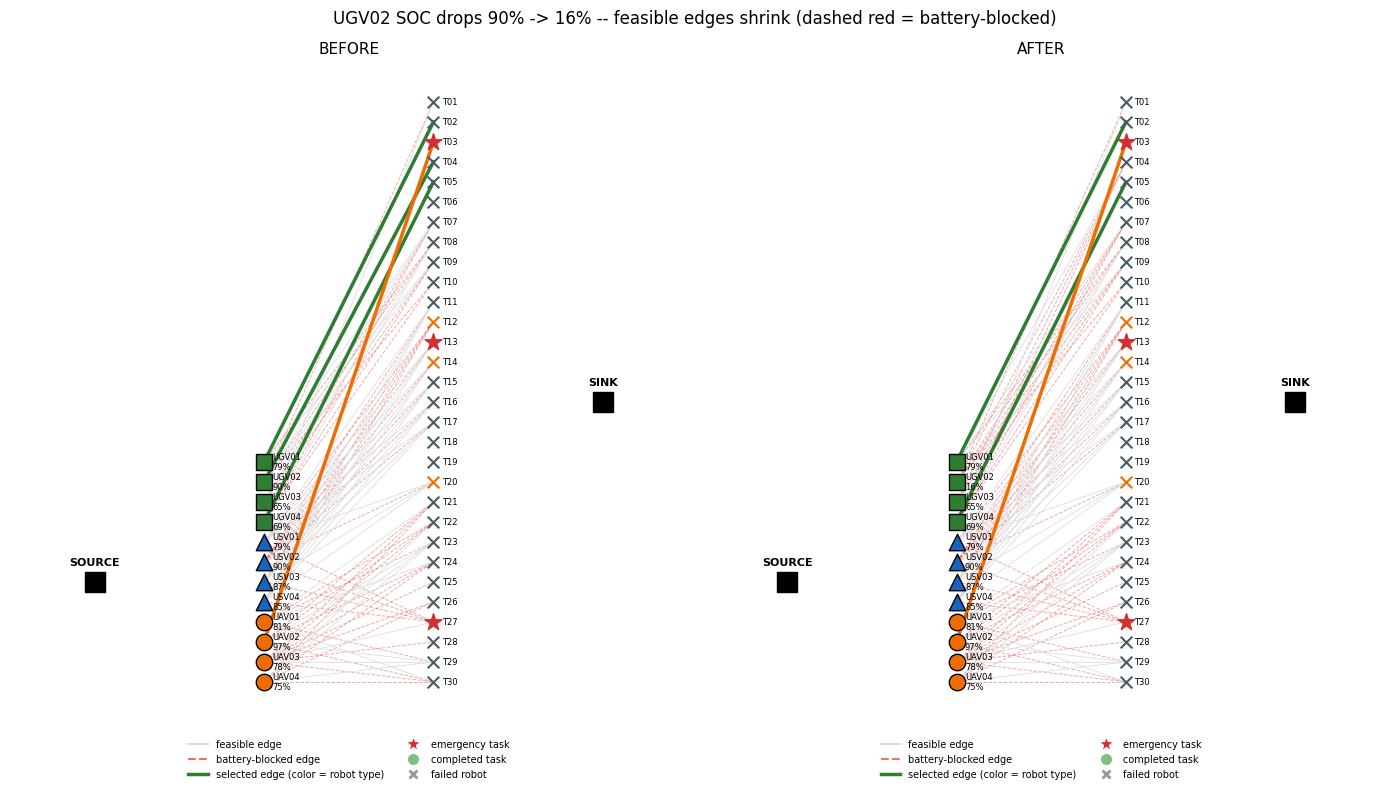

In [4]:
sim_before2 = Simulator(dataset_root=DATASET_ROOT, run_id="final_before2")
sim_before2._allocate(t=0.0)

sim_after2 = copy.deepcopy(sim_before2)
robot = sim_after2.fleet.robots["UGV02"]
before_soc = sim_before2.fleet.robots["UGV02"].soc
robot.soc = 16.0
robot.status, robot.current_task = "IDLE", None
if sim_after2.tm.tasks["T04"].assigned_robot == "UGV02":
    sim_after2.tm.tasks["T04"].status, sim_after2.tm.tasks["T04"].assigned_robot = "PENDING", None

render_before_after(sim_before2, sim_after2,
                     f"UGV02 SOC drops {before_soc:.0f}% -> {robot.soc:.0f}% -- feasible edges shrink (dashed red = battery-blocked)",
                     savepath="../results/day4_before_after_low_battery.png");


### 2c. Robot failure -> its task returns to the graph unassigned

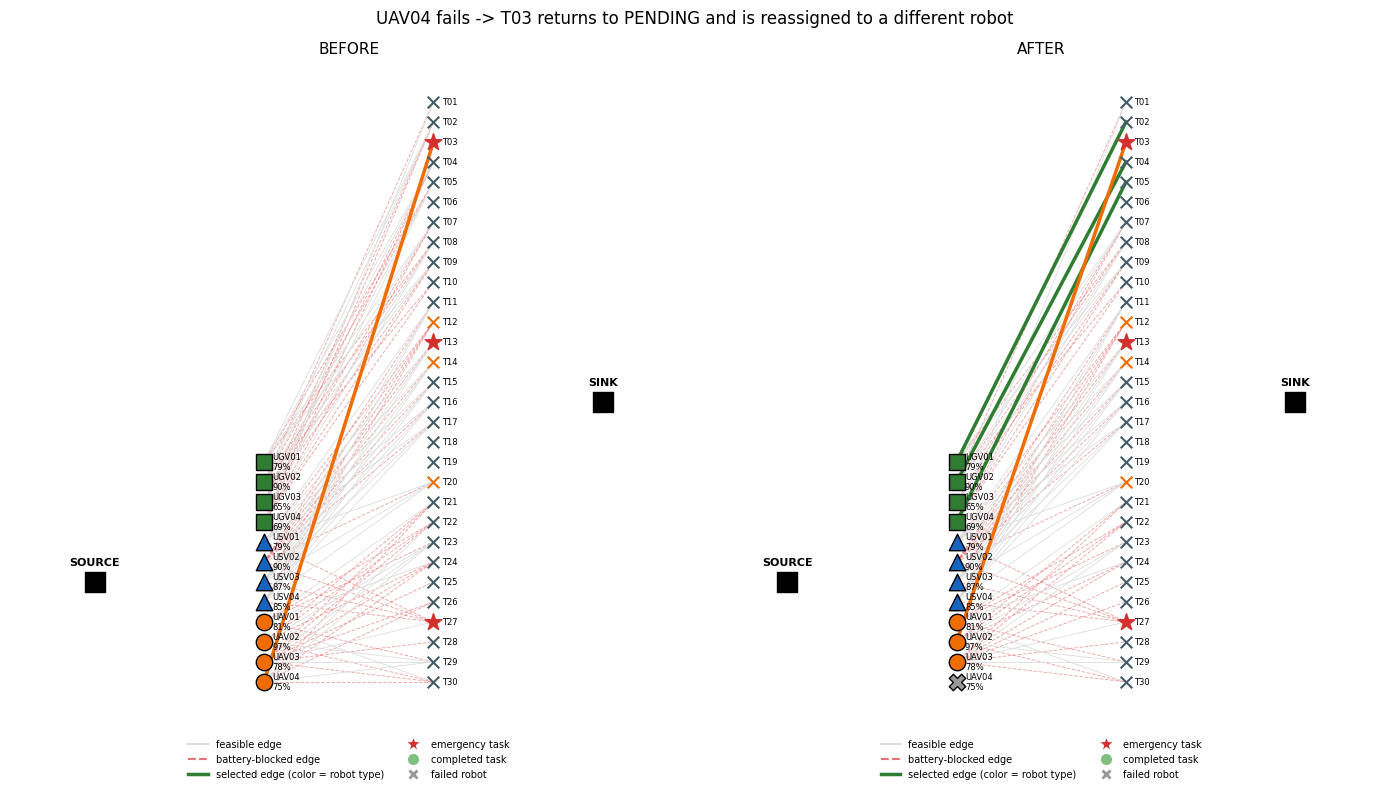

In [5]:
sim_before3 = Simulator(dataset_root=DATASET_ROOT, run_id="final_before3")
robot3 = sim_before3.fleet.robots["UAV04"]
task3 = sim_before3.tm.tasks["T03"]
robot3.status, robot3.current_task = "BUSY", "T03"
task3.status, task3.assigned_robot = "ASSIGNED", "UAV04"

sim_after3 = copy.deepcopy(sim_before3)
fail_ev = Event(event_id="DEMO_FAIL", time=10.0, event_type="ROBOT_FAILURE",
                task_id=None, robot_id="UAV04", zone_id=None, severity=4)
apply_event(fail_ev, sim_after3.fleet, sim_after3.tm, sim_after3.env)
sim_after3._allocate(t=10.0)

render_before_after(sim_before3, sim_after3,
                     "UAV04 fails -> T03 returns to PENDING and is reassigned to a different robot",
                     savepath="../results/day4_before_after_robot_failure.png");


## 3. Full run: live simulation as an animated GIF

Steps the real event-driven simulation across its full timeline
(t=0 to t=166), sampling 12 frames for the dashboard animation. This is
the actual Day 3 engine being visualized, not a separate script.

Saved: ../results/day4_live_simulation.gif
Frame times: [0.0, 19.0, 27.0, 34.0, 37.0, 57.0, 77.0, 107.0, 120.0, 137.0, 151.0, 166.0]


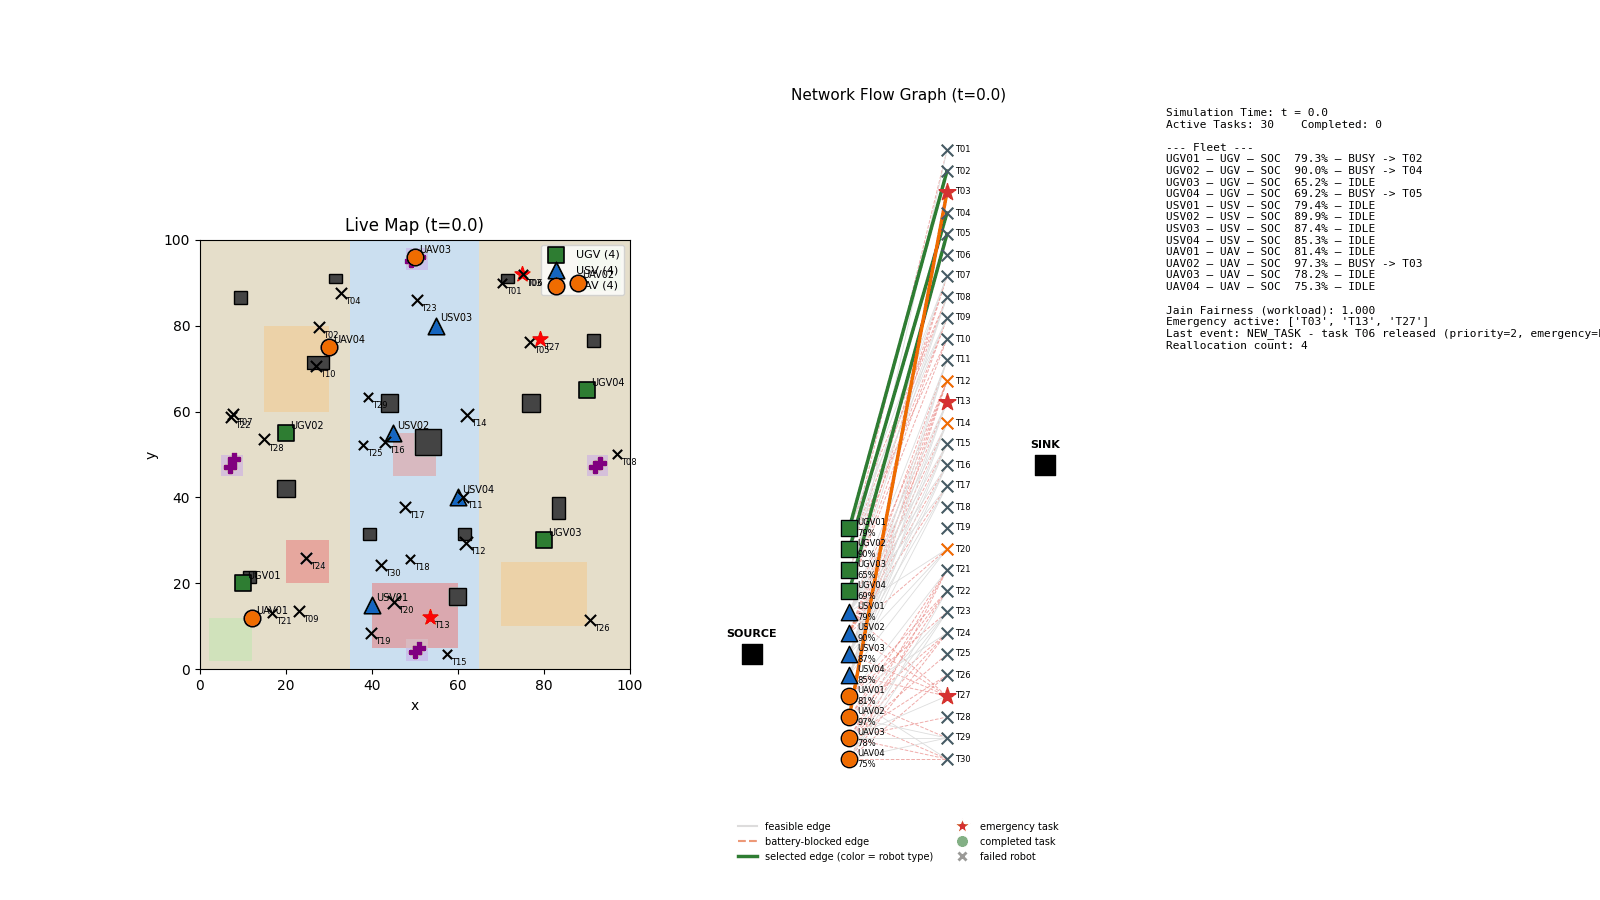

In [6]:
gif_path, frame_times = make_animation(dataset_root=DATASET_ROOT, max_frames=12,
                                         savepath="../results/day4_live_simulation.gif",
                                         run_id="final_animation")
print("Saved:", gif_path)
print("Frame times:", frame_times)
display(Image(filename=gif_path))


## 4. Full run: final summary (numbers, not narrative)

--- Final simulation summary ---
run_id: final_full_run
final_t: 166.0
completed_tasks: 17
cancelled_tasks: 2
unassigned_tasks: 11
failed_robots: 2
reallocation_count: 18
fairness: {'workload_fairness': 0.7941176470588235, 'energy_fairness': 0.6808872758681745, 'battery_stress_fairness': 0.8774260032367697}


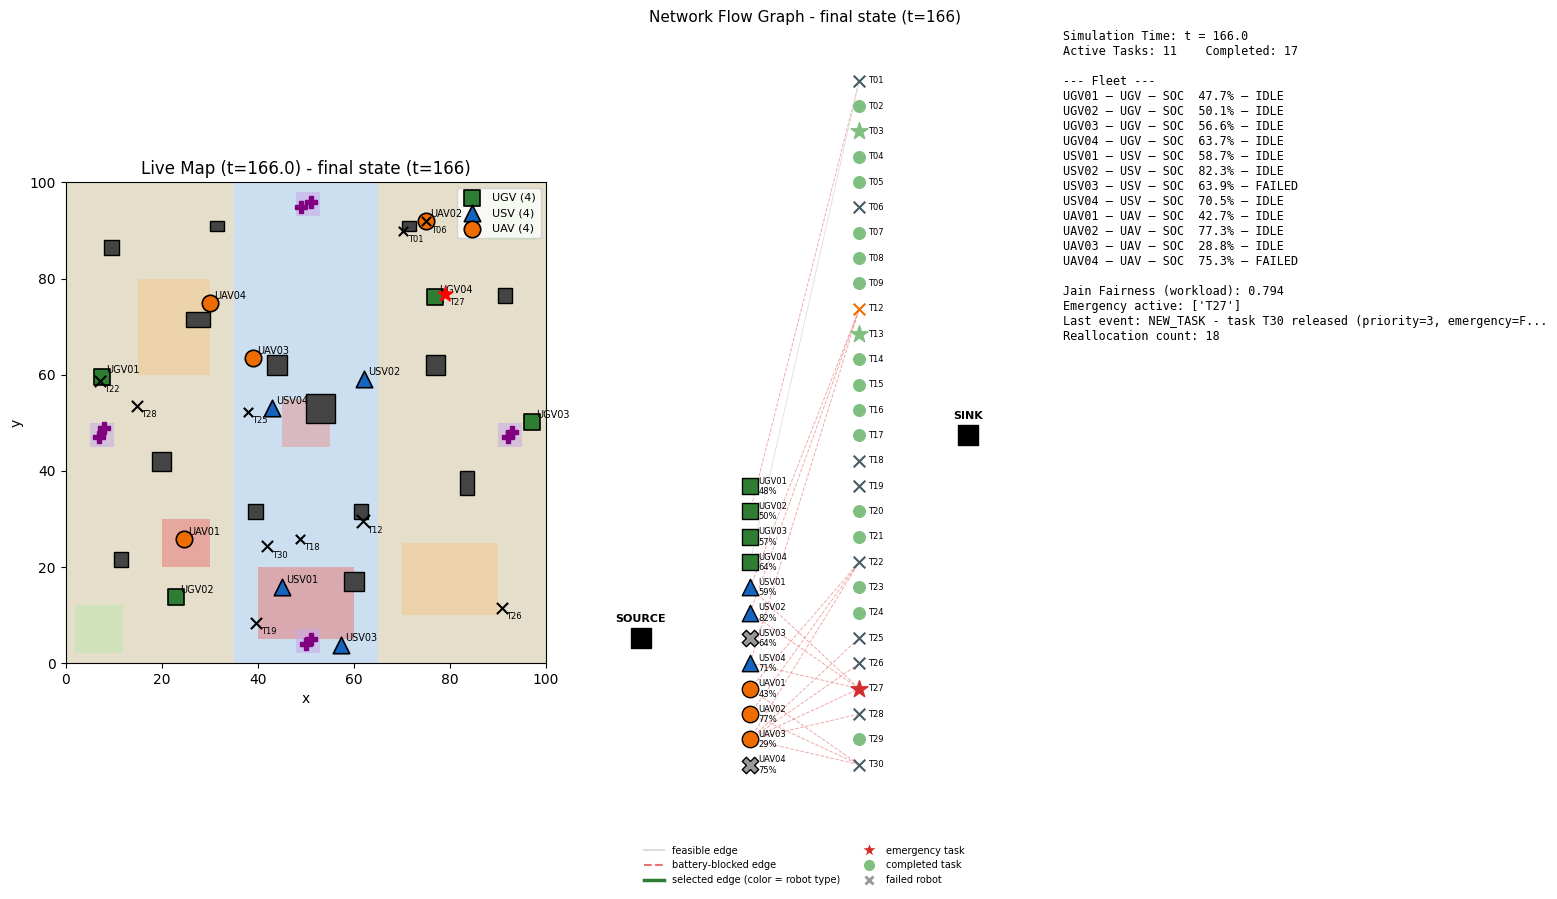

In [7]:
sim_full = Simulator(dataset_root=DATASET_ROOT, run_id="final_full_run")
result = sim_full.run(verbose=False)
print("--- Final simulation summary ---")
for k, v in result.items():
    print(f"{k}: {v}")

fig = render_frame(sim_full, title_suffix=f"- final state (t={sim_full.t:.0f})")
fig.savefig("../results/day4_dashboard_final.png", dpi=130, bbox_inches="tight")


### Final-run summary charts

A visual summary of the complete run: where all 30 tasks ended up, and
how workload/energy were actually distributed across the 12-robot fleet.

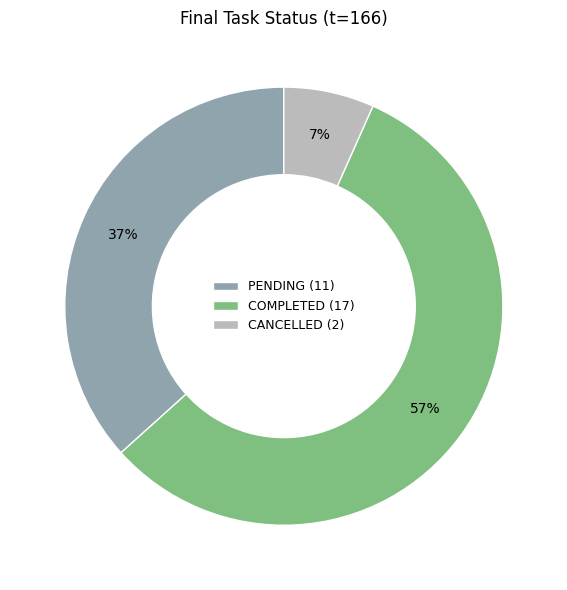

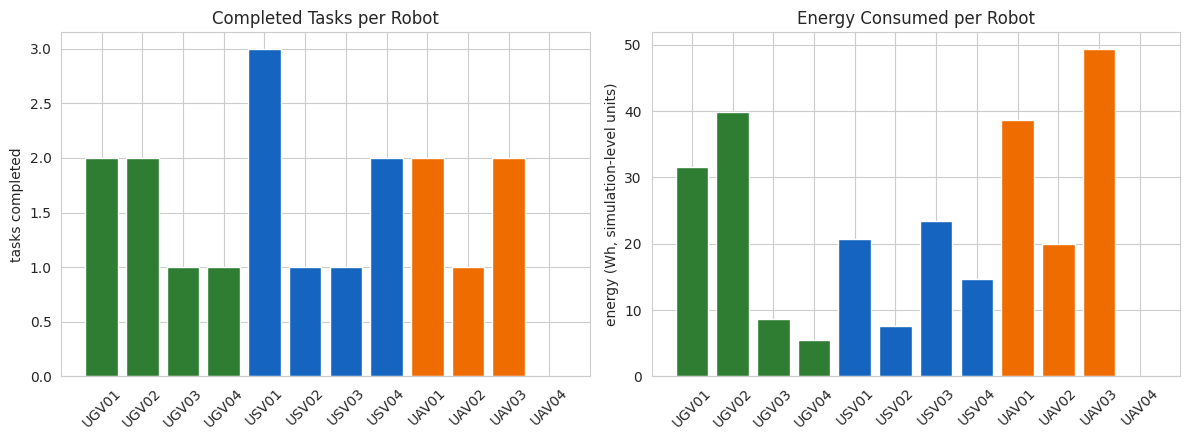

In [8]:
import matplotlib.pyplot as plt
from visualization import plot_task_status_breakdown, plot_workload_and_energy

plot_task_status_breakdown(sim_full.tm, title=f"Final Task Status (t={sim_full.t:.0f})",
                            savepath="../results/day4_final_task_status.png")
plt.show()

robot_types = {rid: r.robot_type for rid, r in sim_full.fleet.robots.items()}
plot_workload_and_energy(sim_full.completed_counts, sim_full.energy_used, robot_types,
                          savepath="../results/day4_final_workload_energy.png")
plt.show()


## Day 4 status — complete

- [x] ML prediction (energy/time/risk), 3 models compared, best saved and
      wired into the auction as an optional blended component
- [x] GAT + PPO graph reinforcement learning, trained from scratch,
      evaluated honestly against the auction baseline
- [x] Full integrated live simulation: map + dynamic network graph +
      side panel, all driven by the real Day 3 engine
- [x] Section 23's before/after graph-update example demonstrated for
      3 different triggers (emergency, low battery, robot failure)
- [x] Animated GIF of the full run

**A complete integrated simulation runs from start to finish**, as
required at the end of Day 4.

**Next (Day 5):** baseline comparisons (greedy, network-flow-only,
+battery, auction-without-ML/RL, full proposed system), ablation studies,
result graphs, and paper-support material.